# 01 · Preprocessing — Obradovic 2021 ccRCC (malignant compartment)

Isolate malignant cells, threshold thin samples, integrate patients (Harmony), embed, remove
detached islands, split the manifold into its transcriptional lobes, and fix one house
orientation for every downstream UMAP. Obradovic et al. (2021) profiled clear-cell renal-cell
carcinoma (ccRCC) by 10x; malignant cells here are almost entirely non-cycling (~1%), so —
unlike Kürten / Lin / Qian — there is **no proliferative lobe confound** to settle. Whether the
gastrulation / somitogenesis / neural-crest developmental axis is confined to one lobe or spans
both is **derived in 02 from the signature geography**, not assumed here, so both lobes are
carried forward. Every tunable choice is *derived from this dataset*, not inherited from the
Puram anchor. Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import scipy.sparse as sp
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)                        # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)    # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Obradovic2021_Kidney | category: Kidney


### Load malignant compartment
Obradovic et al. supply a per-cell `cell_type` annotation in which **Malignant** is an explicit
label (the publication's malignancy call, resolved from the authors' Epithelial clusters); the
loader exposes it as `celltype`, taken directly (per protocol: use the publication's calls).
Counts are `normalize_total`-normalized and `log1p`-transformed by the loader.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())
adata

Loading ../../../../../../data/unzip/CCCA/Data_Obradovic2021_Kidney
Done.
full atlas: (19781, 19234)
malignant: (9369, 19234) | samples: 8
expression: X max 7.60 (log1p of normalize_total UMI counts)


AnnData object with n_obs × n_vars = 9369 × 19234
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'clusters_by_authors', 'celltype'
    uns: 'log1p'

### Sample thresholding — multiplicative gap-finding, with a floor fallback
Per protocol we look for the largest **multiplicative** cliff in the sorted per-sample counts
(the natural separatrix between tumour-bearing samples and spillover). Here the argmax gap
(522→153, ratio 3.41) is a **dominant** cliff: it clearly exceeds the runner-up (973→522, ratio
1.86) — ratio-of-ratios 1.83, above the dominant-cliff bar (1.5) — and the small side (153) sits
below 2×100. The clean-count-gap premise (C3) **is met** for this dataset (unlike the degenerate
Qian / Steele / Peng PDAC cases), so we cut at the **geometric mean** of the cliff (≈282). This
drops the two spillover samples (153, 107) and keeps 6/8 well-populated tumours.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)   # a real spillover cliff?
print('sorted per-sample counts:', n.values)
print('gap ratios:', [f'{int(vals[i])}->{int(vals[i+1])}:{ratios[i]:.2f}' for i in range(len(ratios))])
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
if dominant:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print(f'dominant spillover cliff -> geometric-mean threshold = {thresh}')
else:
    thresh = FLOOR
    print(f'no dominant cliff -> floor >= {FLOOR}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: [2516 2279 1524 1295  973  522  153  107]
gap ratios: ['2516->2279:1.10', '2279->1524:1.50', '1524->1295:1.18', '1295->973:1.33', '973->522:1.86', '522->153:3.41', '153->107:1.43']
argmax gap 522->153 (ratio 3.41); top/second = 1.83; dominant cliff = True
dominant spillover cliff -> geometric-mean threshold = 282
kept 6/8 samples (min per-sample = 522) -> 9109 cells


### Overdispersion, PCA, Harmony integration, embedding
`theta` is chosen by a same-sample-neighbour-fraction sweep (lower = better mixing): mixing
improves sharply from theta=2 to theta=5 and then flattens (theta=10 within noise of theta=5).
ccRCC malignant cells are strongly patient-specific (private CNVs / VHL-driven states), so we take
the strongest integration on the plateau (theta=10) to suppress the batch effect without
collapsing biological structure. PC count (20) and UMAP spread (1.3) follow the 10x precedents
(Kürten / Sun / Lee / Steele / Qian, comparable cell counts).

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

def _same_sample_frac(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([ (s[idx[i]]==s[i]).mean() for i in range(len(s)) ]))
base = _same_sample_frac(adata.obsm['X_pca'][:,:20])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base,
      '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta,
      '(mixing improves sharply to theta=5 then flattens; strongest integration chosen for the',
      'strong patient-specific ccRCC batch effect, without collapsing structure)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 684 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 684
same-sample neighbour fraction | pre-Harmony 0.981 | sweep {2: 0.441, 5: 0.307, 10: 0.302}
selected theta = 10 (mixing improves sharply to theta=5 then flattens; strongest integration chosen for the strong patient-specific ccRCC batch effect, without collapsing structure)


### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop any cell
outside the main connected component — stripping physically detached specks while keeping the
continuous arm termini.

In [6]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

removed 0 cells in 0 detached islands


### Lobe split + labelling (data-driven, marker-based)
Low-resolution Leiden (res=0.15) recovers the manifold's lobes. ccRCC malignant cells here are
almost entirely **non-cycling** (overall cycling fraction ~1%), so the split is **not**
proliferative — the Kürten / Lin cell-cycle confound does not arise. We still label each lobe by
its cycling fraction and proliferation markers to document that both lobes are low-cycling; which
lobe (if any) carries the developmental terminus is decided in 02 (it spans both), so both are
carried forward.

In [7]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
print('cycling fraction per lobe:', adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(3).to_dict())
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
print('proliferation score per lobe:',
      adata.obs.groupby('lobe', observed=True)['prolif_score'].mean().round(3).to_dict())
print('-> both lobes low-cycling (no proliferative confound); lobe identity resolved developmentally in 02')

lobe sizes: {'0': 8207, '1': 902}
overall cycling fraction: 0.012
cycling fraction per lobe: {'0': 0.011, '1': 0.017}
proliferation score per lobe: {'0': -0.014, '1': 0.014}
-> both lobes low-cycling (no proliferative confound); lobe identity resolved developmentally in 02


### House orientation — one consistent layout for every UMAP
The developmental axis is **diagonal** in the raw joint embedding, so all trajectory panels are
shown after a single **rigid rotation** to the house horizontal layout (distance-preserving —
*not* a re-embedding, which would fabricate folds). The orientation is derived **once here**,
stored as `X_umap_lin`, and re-used unchanged by 02/03/04 so every deliverable UMAP shares one
orientation (binding). Two ingredients: (i) rotation angle = the manifold's **axis of maximal
variance**; (ii) the sign places the **developmental origin on the left** so pseudotime runs
left→right once fit in 02. The sign is set from the developmental-module geography — the
**somitogenesis-high / neural-crest-low** pole (the origin) on the left. The three modules are
scored here only to orient the layout; 02 re-scores them canonically for the trajectory.

In [8]:
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
origin_score = S[:,0] - S[:,1]     # pSom-high / Crest-low = developmental origin

xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)          # vt[0] = axis of maximal variance
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[ np.cos(-theta_rot), -np.sin(-theta_rot)],
               [ np.sin(-theta_rot),  np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()                     # origin pole -> left (negative x)
if np.average(xyr[:,0], weights=w) > 0:
    xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg (distances preserved), '
      f'somitogenesis-high origin pole on left; stored as X_umap_lin')
print('raw module means (honest readout):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

manifold aspect (max/min std): 1.18
house orientation: rigid rotation -116.2deg (distances preserved), somitogenesis-high origin pole on left; stored as X_umap_lin
raw module means (honest readout): {'Gast': 0.0242, 'pSom': 0.0994, 'Crest': -0.075}


### Gate 1 — batch mixing & manifold continuity
Samples must intermix (no per-patient islands) on one continuous manifold. The read is made on the
regenerated embedding itself plus a per-neighbourhood metric (iLISI), not a scalar alone; the
deliverable `samples.pdf` follows.

In [9]:
n_samp = adata.obs['sample'].nunique()
def _ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]
    out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta=10) {il_post:.2f} of {n_samp} samples')
print(f'{n_samp} samples share one continuous manifold (one connected component after island removal).')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 4.28 of 6 samples
6 samples share one continuous manifold (one connected component after island removal).
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS


### Save processed data
Coerce mixed-type object metadata columns to numeric where possible (else string) so the manifold
is h5ad-serializable; categorical columns (sample, lobe, cell-cycle) are protected so they render
as discrete legends, not colorbars.

In [10]:
protect = {'sample','lobe','celltype','cell_type','cell_cycle_phase','source','disease','clusters_by_authors','mp_top','mp_assignment'}
for c in adata.obs.columns:
    if c in protect:
        adata.obs[c] = adata.obs[c].astype(str).astype('category'); continue
    col = adata.obs[c]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[c] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (9109, 16286)


### Sample-integration figure (deliverable)

saved samples.pdf | cells: 9109


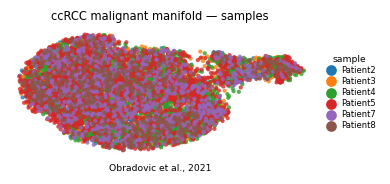

In [11]:
# House style (figsize=(3.5,1.5) horizontal strip, size=30) to match every other panel.
# Colour = sample: intermixing across the strip is the Gate-1 batch-integration evidence,
# shown on the house orientation (X_umap_lin) so this panel shares one orientation with 02/03/04.
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('ccRCC malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Obradovic et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])